In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from demand_forecasting.data import read_source_data
df = read_source_data('Data/data.csv')
df.head()

,Scope,Data type,Date,Time,Timestamp,Consumption (MW),D-1 forecast (MW),D forecast (MW),Oil (MW),Coal (MW),Gas (MW),Nuclear (MW),Wind (MW),Solar (MW),Hydro (MW),Pumping (MW),Bioenergy (MW),Physical exchanges (MW),CO2 intensity (g/kWh),Commercial exchanges - England (MW),Commercial exchanges - Spain (MW),Commercial exchanges - Italy (MW),Commercial exchanges - Switzerland (MW),Commercial exchanges - Germany/Belgium (MW),Oil - combustion turbines (MW),Oil - cogeneration (MW),Oil - other (MW),Gas - combustion turbines (MW),Gas - cogeneration (MW),Gas - combined cycle (MW),Gas - other (MW),Hydro - run-of-river and pondage (MW),Hydro - reservoirs (MW),Hydro - pumped-storage generation (MW),Bioenergy - waste (MW),Bioenergy - biomass (MW),Bioenergy - biogas (MW)
0,France,Consolidated data,2026-06-30,23:45,2026-06-30T23:45:00+02:00,NaN,48050,48200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-4028.0,1623.0,-2809.0,-1827.0,-2186,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,France,Consolidated data,2026-06-30,23:30,2026-06-30T23:30:00+02:00,48906.0,49100,49400,51.0,14.0,5051.0,37753.0,4834.0,1.0,9264.0,-5.0,1113.0,-9164.0,35.0,-4028.0,1698.0,-2444.0,-1827.0,-2010,15.0,33.0,3.0,92.0,169.0,4744.0,46.0,3658.0,2910.0,2695.0,406.0,410.0,297.0
2,France,Consolidated data,2026-06-30,23:15,2026-06-30T23:15:00+02:00,NaN,49900,50300,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-4028.0,1626.0,-2939.0,-1827.0,-1981,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,France,Consolidated data,2026-06-30,23:00,2026-06-30T23:00:00+02:00,49944.0,50700,51200,51.0,14.0,5088.0,37710.0,4853.0,1.0,9615.0,-40.0,1118.0,-8701.0,36.0,-4028.0,1700.0,-2445.0,-1827.0,-2224,15.0,33.0,3.0,95.0,178.0,4748.0,67.0,3697.0,2999.0,2918.0,410.0,409.0,300.0
4,France,Consolidated data,2026-06-30,22:45,2026-06-30T22:45:00+02:00,NaN,50000,50550,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-3931.0,998.0,-1772.0,-1452.0,-3140,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
data = df.copy()
data = data.dropna(subset=["Consumption (MW)"]).copy()
data.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
Index: 254160 entries, 1 to 508319
Data columns (total 37 columns):
 #   Column                                       Non-Null Count   Dtype  
---  ------                                       --------------   -----  
 0   Scope                                        254160 non-null  str    
 1   Data type                                    254160 non-null  str    
 2   Date                                         254160 non-null  str    
 3   Time                                         254160 non-null  str    
 4   Timestamp                                    254160 non-null  str    
 5   Consumption (MW)                             254160 non-null  float64
 6   D-1 forecast (MW)                            254160 non-null  int64  
 7   D forecast (MW)                              254160 non-null  int64  
 8   Oil (MW)                                     254160 non-null  float64
 9   Coal (MW)                                    254160 non-null  float64
 10  

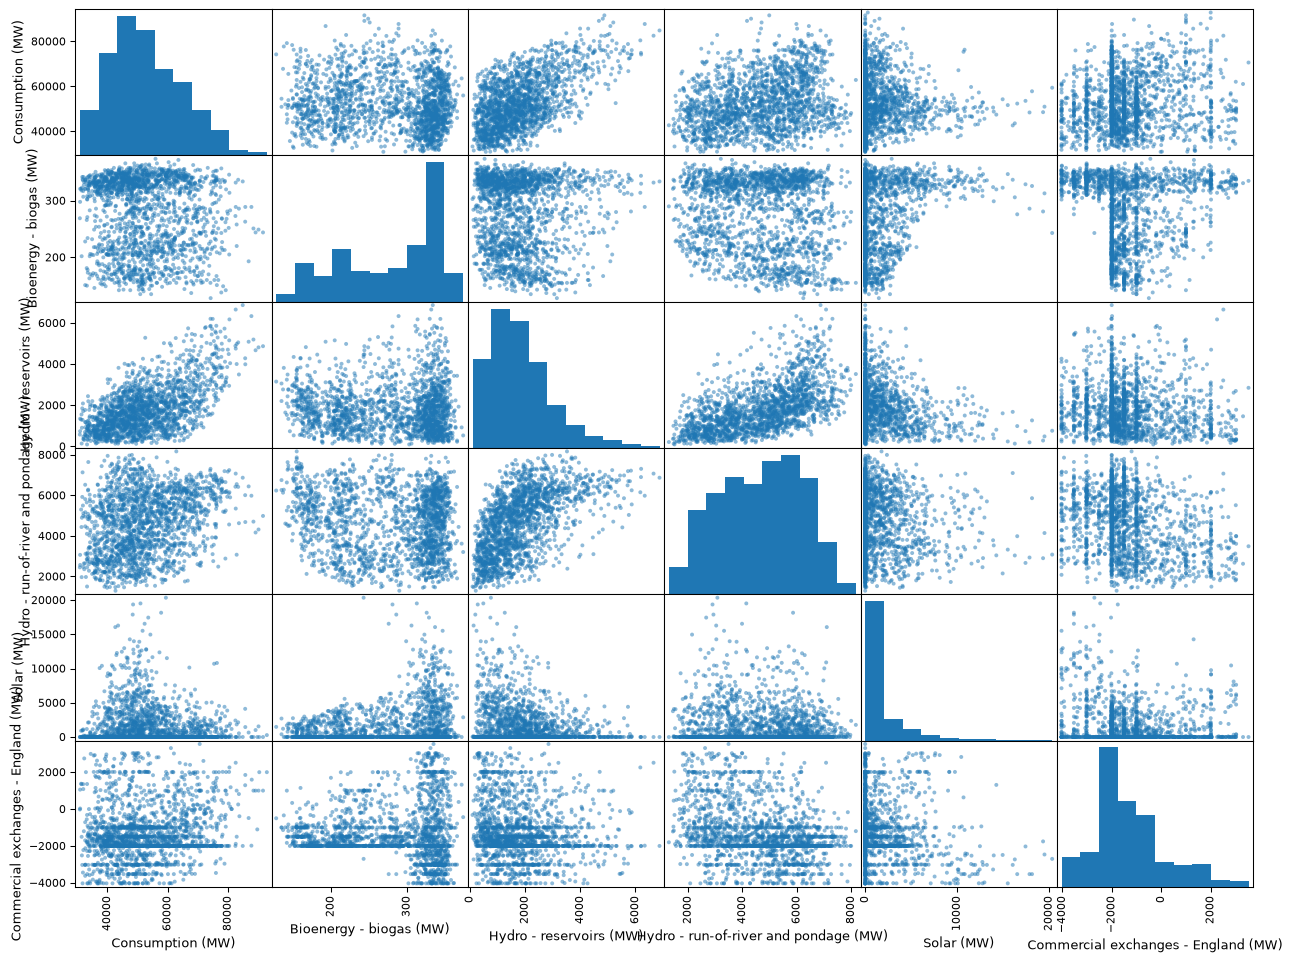

In [4]:
from pandas.plotting import scatter_matrix
attributes = ["Consumption (MW)", "Bioenergy - biogas (MW)", "Hydro - reservoirs (MW)",
"Hydro - run-of-river and pondage (MW)", "Solar (MW)", "Commercial exchanges - England (MW)"]
# Sample for readable plots and economical rendering.
scatter_matrix(data[attributes].sample(n=min(2000, len(data)), random_state=42), figsize=(16, 12))
plt.show()

# Additional exploration for day-ahead forecasting

This section supplements the initial exploration with diagnostics related to the benchmark: data quality and frequency, temporal changes, calendar profiles, extreme values, and the relevance of D−1 and D−7 histories.

Quality checks cover the entire source file. Consumption statistics and charts use **development data only**, through April 26, 2024, keeping them separate from the test period. MW measures power: the daily means shown here are not energy values in MWh.


In [5]:
from demand_forecasting.data import read_source_data
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from first_regression import load_development_data

EDA_DIR = Path("results/eda")
EDA_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
TARGET = "Consumption (MW)"
raw = read_source_data("Data/data.csv", columns=["Date", "Time", TARGET])
raw["Date"] = pd.to_datetime(raw["Date"], errors="raise")
raw["minute"] = raw["Time"].str[-2:].astype(int)
_, _, development_dates = load_development_data()
development_end = pd.Timestamp(development_dates[-1])


## 1. Data quality and actual measurement frequency

The source contains quarter-hourly rows, but consumption is populated at half-hourly intervals. Interpret missingness together with the measurement minute. We also check duplicate timestamps, incomplete days, and calendar gaps, without automatic interpolation.


In [6]:
quality = pd.Series({
    "Raw rows": len(raw),
    "Missing consumption": raw[TARGET].isna().sum(),
    "Missing consumption (%)": 100 * raw[TARGET].isna().mean(),
    "Duplicate Date/Time rows": raw.duplicated(["Date", "Time"]).sum(),
}, name="Value").to_frame()
display(quality.round(2))
by_minute = raw.groupby("minute")[TARGET].agg(
    rows="size", observed="count")
by_minute["Missing (%)"] = 100 * (1 - by_minute["observed"] / by_minute["rows"])
display(by_minute.round(2))
observed = raw.dropna(subset=[TARGET]).sort_values(["Date", "Time"]).copy()
counts = observed.groupby("Date").size()
expected_dates = pd.date_range(raw["Date"].min(), raw["Date"].max(), freq="D")
expected_hours = {f"{hour:02d}:{minute:02d}" for hour in range(24) for minute in [0, 30]}
invalid_days = observed.groupby("Date")["Time"].agg(lambda x: set(x) != expected_hours)
checks = pd.Series({
    "First source date": str(raw["Date"].min().date()),
    "Last source date": str(raw["Date"].max().date()),
    "Observed days": len(counts),
    "Days without exactly 48 readings": int(counts.ne(48).sum()),
    "Days with unexpected time slots": int(invalid_days.sum()),
    "Missing days": len(expected_dates.difference(counts.index)),
    "Infinite values": int((~np.isfinite(observed[TARGET])).sum()),
    "Nonpositive consumption": int(observed[TARGET].le(0).sum()),
}, name="Value").to_frame()
display(checks)
assert counts.eq(48).all() and not invalid_days.any()
assert len(expected_dates.difference(counts.index)) == 0
quality.to_csv(EDA_DIR / "quality_summary.csv")
by_minute.to_csv(EDA_DIR / "missing_by_minute.csv")


,Value
Raw rows,508320.0
Missing consumption,254160.0
Missing consumption (%),50.0
Duplicate Date/Time rows,0.0


,rows,observed,Missing (%)
minute,,,
0,127080,127080,0.0
15,127080,0,100.0
30,127080,127080,0.0
45,127080,0,100.0


,Value
First source date,2012-01-01
Last source date,2026-06-30
Observed days,5295
Days without exactly 48 readings,0
Days with unexpected time slots,0
Missing days,0
Infinite values,0
Nonpositive consumption,0


## 2. Scale and temporal evolution

Daily consumption and the 30-day rolling mean reveal cycles and changes in level. Quantiles describe dispersion without automatically treating peaks as anomalies.


Development period explored : 2012-01-01 → 2024-04-26 ; 4500 days.


,Consumption (MW)
count,216000.00
mean,53510.84
std,11855.82
min,29124.00
1%,33035.00
5%,36646.00
50%,51800.00
95%,75256.00
99%,82977.04
max,102098.00


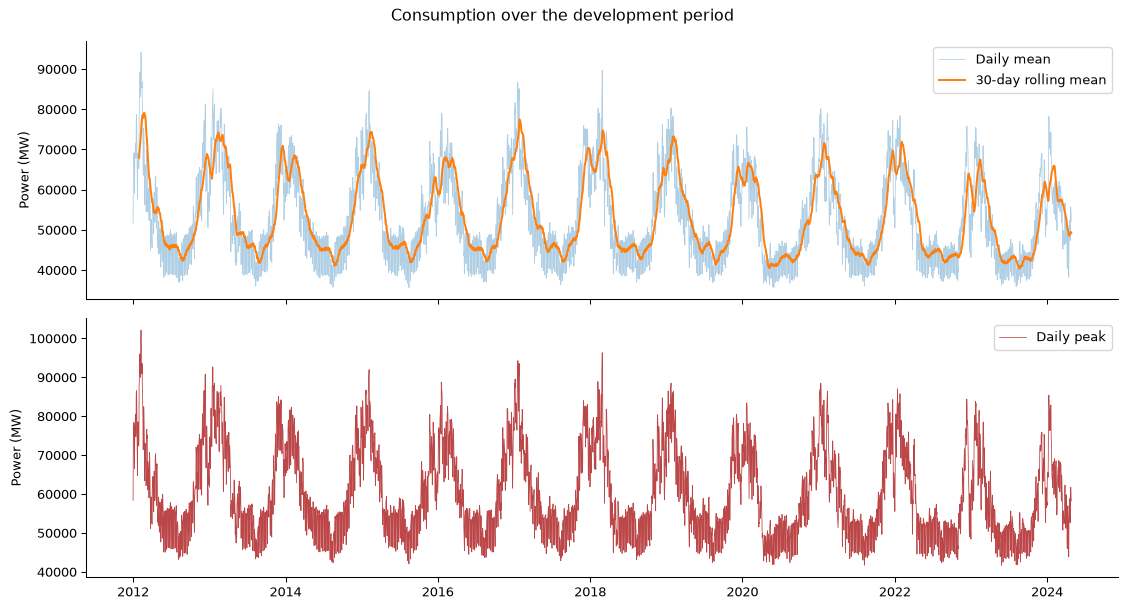

In [7]:
dev = observed.loc[observed["Date"].le(development_end)].copy()
dev["hour"] = dev["Time"].str[:2].astype(int) + dev["minute"] / 60
dev["weekday"] = dev["Date"].dt.dayofweek
dev["month"] = dev["Date"].dt.month
daily = dev.groupby("Date")[TARGET].agg(mean="mean", minimum="min", peak="max")
daily["amplitude"] = daily["peak"] - daily["minimum"]
profile = dev.pivot(index="Date", columns="Time", values=TARGET).sort_index(axis=1)
assert profile.shape[1] == 48 and not profile.isna().any().any()
display(dev[TARGET].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(2).to_frame())
print(f"Development period explored : {daily.index.min().date()} → {daily.index.max().date()} ; {len(daily)} days.")
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
axes[0].plot(daily.index, daily["mean"], alpha=0.35, lw=0.6, label="Daily mean")
axes[0].plot(daily.index, daily["mean"].rolling(30).mean(), lw=1.5, label="30-day rolling mean")
axes[0].set_ylabel("Power (MW)")
axes[0].legend()
axes[1].plot(daily.index, daily["peak"], color="#bc4749", lw=0.6, label="Daily peak")
axes[1].set_ylabel("Power (MW)")
axes[1].legend()
fig.suptitle("Consumption over the development period")
fig.tight_layout()
fig.savefig(EDA_DIR / "time_series.png", dpi=150)
plt.show()
daily.to_csv(EDA_DIR / "daily_statistics.csv")


## 3. Daily and calendar profiles

Compare all seven weekdays and four seasons. Seasonal bands show 10–90% observation quantiles at each half-hour, rather than model uncertainty. Calendar averages combine several years and may conceal structural changes.


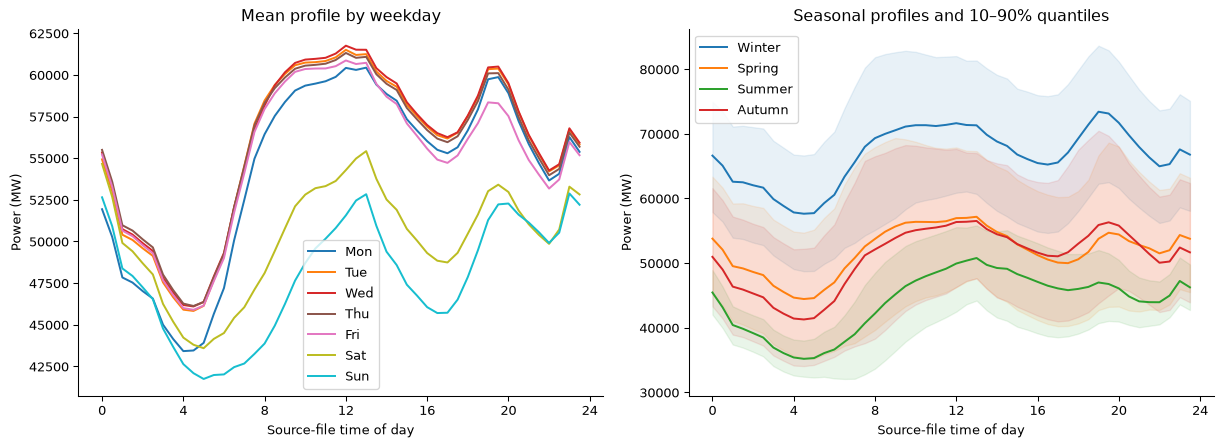

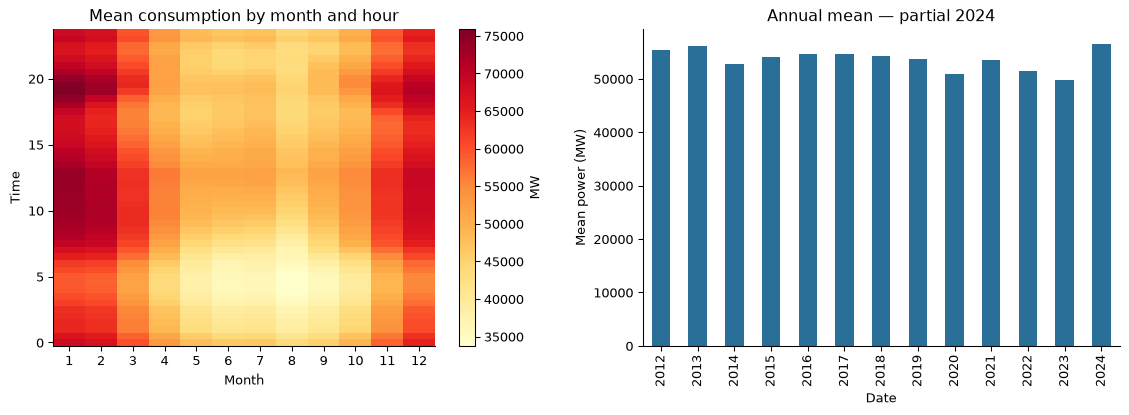

,mean,readings,days
Date,,,
2012,55396.96,17568,366
2013,56185.53,17520,365
2014,52779.50,17520,365
2015,54012.88,17520,365
2016,54681.29,17568,366
2017,54685.46,17520,365
2018,54283.22,17520,365
2019,53707.44,17520,365
2020,50840.47,17568,366


In [8]:
dev["season"] = dev["month"].map({12:"Winter",1:"Winter",2:"Winter",3:"Spring",4:"Spring",5:"Spring",6:"Summer",7:"Summer",8:"Summer",9:"Autumn",10:"Autumn",11:"Autumn"})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
weekday_profiles = dev.groupby(["hour", "weekday"])[TARGET].mean().unstack()
weekday_profiles.columns = WEEKDAYS
weekday_profiles.plot(ax=axes[0], colormap="tab10")
axes[0].set_title("Mean profile by weekday")
axes[0].set_ylabel("Power (MW)")
for season in ["Winter", "Spring", "Summer", "Autumn"]:
    group = dev.loc[dev["season"].eq(season)].groupby("hour")[TARGET]
    mean = group.mean()
    line, = axes[1].plot(mean.index, mean, label=season)
    axes[1].fill_between(mean.index, group.quantile(0.1), group.quantile(0.9), alpha=0.10, color=line.get_color())
axes[1].set_title("Seasonal profiles and 10–90% quantiles")
axes[1].set_ylabel("Power (MW)")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("Source-file time of day")
    ax.set_xticks(range(0, 25, 4))
fig.tight_layout()
fig.savefig(EDA_DIR / "calendar_profiles.png", dpi=150)
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
month_hour = dev.groupby(["hour", "month"])[TARGET].mean().unstack()
im = axes[0].imshow(month_hour, origin="lower", aspect="auto", cmap="YlOrRd", extent=[0.5,12.5,-0.25,23.75])
axes[0].set_xticks(range(1,13))
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Time")
axes[0].set_title("Mean consumption by month and hour")
fig.colorbar(im, ax=axes[0], label="MW")
annual = dev.groupby(dev["Date"].dt.year)[TARGET].agg(mean="mean", readings="size")
annual["days"] = annual["readings"] // 48
annual["mean"].plot.bar(ax=axes[1], color="#2a6f97")
axes[1].set_ylabel("Mean power (MW)")
axes[1].set_title("Annual mean — partial 2024")
fig.tight_layout()
fig.savefig(EDA_DIR / "seasonality.png", dpi=150)
plt.show()
display(annual.round(2))


## 4. Distributions and extreme days

Days with the largest peaks and daily ranges deserve inspection. They are retained: extreme observations may reflect real conditions. These curves alone cannot establish weather-related or economic causes.


Five days with the highest peaks :
Five days with the largest ranges :


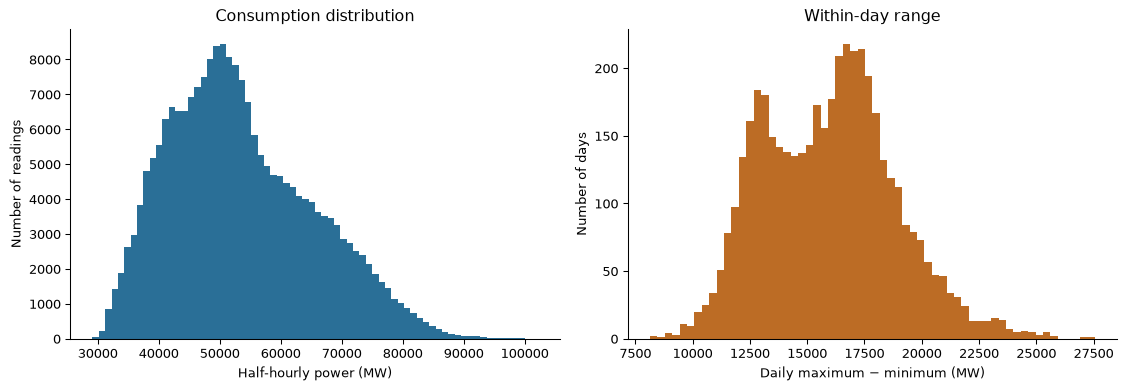

,mean,minimum,peak,amplitude
Date,,,,
2012-02-08,94096.69,85413.0,102098.0,16685.0
2012-02-07,91176.27,81816.0,100430.0,18614.0
2012-02-09,92868.15,86339.0,99420.0,13081.0
2012-02-10,90262.65,83292.0,96698.0,13406.0
2018-02-28,89600.08,80461.0,96272.0,15811.0


,mean,minimum,peak,amplitude
Date,,,,
2014-12-01,64400.83,48119.0,75679.0,27560.0
2012-01-02,60683.65,46294.0,73263.0,26969.0
2013-01-14,76181.92,61631.0,87328.0,25697.0
2017-12-11,70550.08,55741.0,81429.0,25688.0
2018-10-29,63478.29,48394.0,73992.0,25598.0


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
dev[TARGET].plot.hist(bins=70, ax=axes[0], color="#2a6f97")
axes[0].set_xlabel("Half-hourly power (MW)")
axes[0].set_ylabel("Number of readings")
axes[0].set_title("Consumption distribution")
daily["amplitude"].plot.hist(bins=60, ax=axes[1], color="#bc6c25")
axes[1].set_xlabel("Daily maximum − minimum (MW)")
axes[1].set_ylabel("Number of days")
axes[1].set_title("Within-day range")
fig.tight_layout()
fig.savefig(EDA_DIR / "distributions.png", dpi=150)
plt.show()
print("Five days with the highest peaks :")
display(daily.nlargest(5, "peak").round(2))
print("Five days with the largest ranges :")
display(daily.nlargest(5, "amplitude").round(2))


## 5. Dependence on previous days and baselines

D−1 and D−7 persistence errors use the **same target days**, starting with the eighth available day. Correlations use daily mean power; MAE uses all 48 half-hours. High correlation does not guarantee low forecasting error.

This descriptive development analysis neither replaces chronological cross-validation nor establishes causality.


Hardest target weekday for each persistence model :
D−1    Mon
D−7    Mon


,MAE (MW),RMSE (MW)
D−1,2963.49,4389.73
D−7,3564.76,5189.92


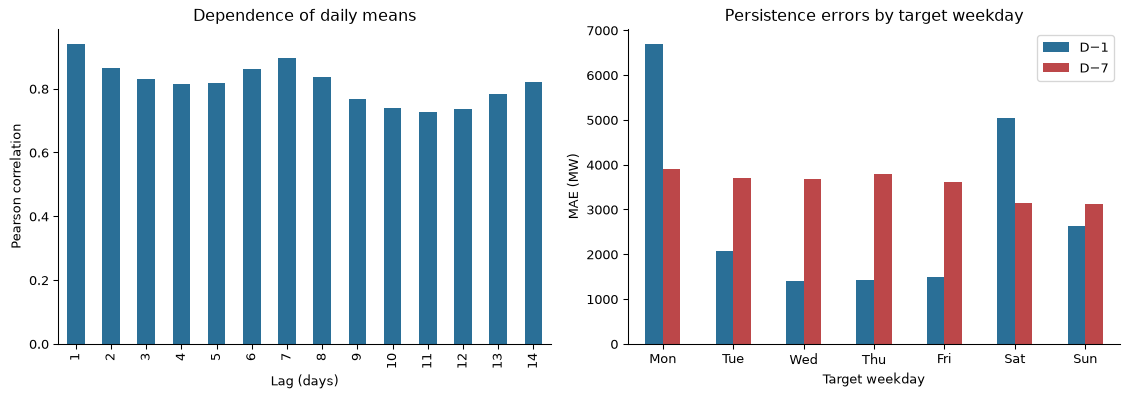

In [10]:
lag_rows = []
errors = pd.DataFrame(index=profile.index[7:])
truth = profile.iloc[7:].to_numpy()
for lag in range(1, 15):
    aligned = pd.concat([daily["mean"], daily["mean"].shift(lag)], axis=1).dropna()
    lag_rows.append({"Lag (days)": lag, "Daily mean correlation": aligned.iloc[:,0].corr(aligned.iloc[:,1])})
for lag in [1, 7]:
    prediction = profile.shift(lag).iloc[7:].to_numpy()
    errors[f"D−{lag}"] = np.abs(truth - prediction).mean(axis=1)
lag_summary = pd.DataFrame(lag_rows).set_index("Lag (days)")
baselines = pd.DataFrame({"MAE (MW)": errors.mean()})
for lag in [1,7]:
    residual = truth - profile.shift(lag).iloc[7:].to_numpy()
    baselines.loc[f"D−{lag}", "RMSE (MW)"] = np.sqrt(np.mean(residual**2))
display(baselines.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
lag_summary.plot.bar(ax=axes[0], legend=False, color="#2a6f97")
axes[0].set_ylabel("Pearson correlation")
axes[0].set_title("Dependence of daily means")
weekday_errors = errors.groupby(errors.index.dayofweek).mean()
weekday_errors.index = WEEKDAYS
weekday_errors.plot.bar(ax=axes[1], color=["#2a6f97", "#bc4749"])
axes[1].set_title("Persistence errors by target weekday")
axes[1].set_ylabel("MAE (MW)")
axes[1].set_xlabel("Target weekday")
axes[1].tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(EDA_DIR / "lags_and_baselines.png", dpi=150)
plt.show()
baselines.to_csv(EDA_DIR / "development_baselines.csv")
weekday_errors.to_csv(EDA_DIR / "baseline_error_by_weekday.csv")
print("Hardest target weekday for each persistence model :")
print(weekday_errors.idxmax().to_string())


## Implications for modeling

- Calendar cycles motivate testing target weekday and several historical days; their contribution must still be measured with temporal validation.
- Dependence between successive days motivates persistence baselines. Comparing D−1 and D−7 avoids assuming that the previous week is the best reference.
- Changes in level and seasonality motivate expanding windows and error analysis by period.
- Peaks and large daily ranges help interpret the gap between MAE and RMSE. Residual diagnostics would be needed to attribute large model errors to those days.
- Contemporaneous generation and exchange columns in the source are excluded from the benchmark inputs. Their availability at forecast time must be established before adding them.

Time-of-day labels follow the source Date/Time fields, as in preprocessing. This exploration does not validate the provider's timezone convention.


## Findings from this run

- Each of the 5,295 source days has 48 observed consumption values, with no missing days or duplicate Date/Time rows. The 50% raw missingness occurs at minutes 15 and 45; readings at minutes 00 and 30 are complete.
- Mean profiles are higher in winter than summer and lower on weekends than weekdays. These are descriptive differences; no weather variables are used here.
- D−1 errors rise sharply on Mondays and Saturdays, at transitions between weekdays and weekends. This supports examining the target-day calendar.
- On the same development days, D−1 has a **2,963.49 MW MAE**, compared with **3,564.76 MW for D−7**. Weekly periodicity alone does not determine the best reference.

These descriptive figures cover development days with seven days of history. They differ from cross-validation scores, which cover only the outer validation windows.
